# Processing sur les données

**Objectif** :  dans ce notebook, on va chercher à sélectionner les données utiles pour les analyses demandés et la prédiction. Le travail se coupera en plusieurs parties :

| **Etape**| **Apprend-elle quelque chose des données ?** | **Commentaire**| 
| --| -- | --| 
| 1. Suppression des features dont plus de 80% d'instance manquante|Non |Au tout début | 
| 2. Analyse descriptive des données| Oui | Utilisation de l'ACP, la corrélation, etc. | 
| 3. Sélection des freatures cibles, et split des données en train/test| Non | Le choix classique est : 80% de train et 20% de test| 
| 4. Traitement des features dont moins de 80% d'instances manquante| Oui| A ne faire que sur `X_train` et pas `y_train` en plus (comme dans le TD), car toute imputation sera appliquer à `X_test`. Il ne faut pas compléter `X_test` à l'aide des réponses, sinon le test est faux (= construire tes tests avec la bonne réponse, donc à la fin, c'est forcément très beau le score).| 



## 0. Chargement des données

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor   # ou le modèle que tu utilises
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin, OneToOneFeatureMixin
from sklearn.decomposition import PCA

In [2]:
path_data_processed = Path("..") / "1. Données" / "02_intermediate"
path_data_correspondance = path_data_processed / "correspondance_between_names_units.csv"

df = pd.read_csv(path_data_processed / "welddb_processed.csv", sep = ";")
correspondance_between_names_units = pd.read_csv(path_data_correspondance, sep = ";")

In [3]:
# détermination des rôles des colonnes
roles = {
    "TARGETS": "Quality indicator",
    "TEST_CONDITION": "Test condition",
    "CHEMISTRY": "Molecular concentration"
}

for variable, role in roles.items():
    globals()[variable] = correspondance_between_names_units.loc[
        correspondance_between_names_units["Role"] == role, "Feature"
    ].tolist()

ID_COL = "Weld ID"


PROCESS_NUM = correspondance_between_names_units.loc[
    (correspondance_between_names_units["Types de variables"] == "float64")
    & (~correspondance_between_names_units["Feature"].isin(TARGETS + [ID_COL] + CHEMISTRY)),
    "Feature"
].tolist()

PROCESS_CAT = correspondance_between_names_units.loc[
    (correspondance_between_names_units["Types de variables"] == "str")
    & (~correspondance_between_names_units["Feature"].isin(TARGETS + [ID_COL] + CHEMISTRY)),
    "Feature"
].tolist()

# Catégorielles
df["Type of weld"] = df["Type of weld"].replace({"ShMA": "MMA"})

## 1. Valeurs manquantes

Démarche du cours (CM0, *Dealing with missing values*) :
1. quel est le **pourcentage** de manquants par variable ?
2. **par groupe** de population ?
3. y a-t-il un **prédicteur** des valeurs manquantes ?
→ on en déduit une hypothèse MCAR / MAR / MNAR puis une stratégie.

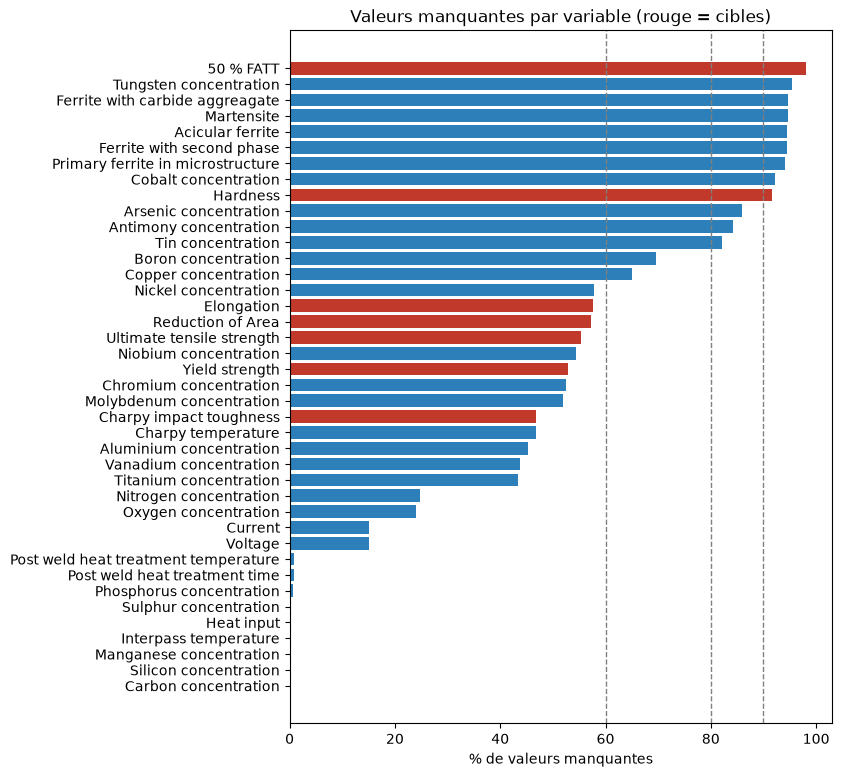

In [4]:
FEATURES_NUM = CHEMISTRY + PROCESS_NUM
miss = (df[FEATURES_NUM + TARGETS].isna().mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(7, 9))
colors = ["#c0392b" if c in TARGETS else "#2c7fb8" for c in miss.index]
ax.barh(miss.index, miss.values, color=colors)
for x in (60, 80, 90):
    ax.axvline(x, ls="--", lw=1, color="grey")
ax.set_xlabel("% de valeurs manquantes")
ax.set_title("Valeurs manquantes par variable (rouge = cibles)")
plt.show()

**Par groupe : les manquants dépendent-ils de la source ?**

Pour chaque variable, on regarde, source par source, si elle est *toujours* renseignée, *jamais* renseignée, ou *parfois*. Si la quasi-totalité des sources sont « tout ou rien », c'est que la présence d'une valeur dépend de **la publication** (ce que les auteurs ont choisi de mesurer), pas du hasard.

In [5]:
source = df[ID_COL]
by_source = df[FEATURES_NUM + TARGETS].isna().groupby(source).mean()
all_or_nothing = ((by_source == 0) | (by_source == 1)).mean() * 100
n_sources_obs = (by_source < 1).sum()

miss_table = pd.DataFrame({
    "% manquant": (df[FEATURES_NUM + TARGETS].isna().mean() * 100).round(1),
    "nb valeurs observées": df[FEATURES_NUM + TARGETS].notna().sum(),
    "nb sources où observée": n_sources_obs,
    "% sources 'tout ou rien'": all_or_nothing.round(0),
}).sort_values("% manquant", ascending=False)
miss_table

,% manquant,nb valeurs observées,nb sources où observée,% sources 'tout ou rien'
50 % FATT,98.1,31,3,99.0
Tungsten concentration,95.5,75,26,100.0
Ferrite with carbide aggreagate,94.6,89,8,95.0
Martensite,94.6,89,8,95.0
Acicular ferrite,94.6,90,8,95.0
Ferrite with second phase,94.6,90,8,95.0
Primary ferrite in microstructure,94.1,98,9,94.0
Cobalt concentration,92.2,129,27,100.0
Hardness,91.6,138,5,98.0
Arsenic concentration,85.8,234,8,100.0


**Interprétation (hypothèse de mécanisme)**

- Pour les **entrées**, ≈ 99 % des sources sont « tout ou rien » (pour les cibles ≈ 85 %) : la probabilité qu'une valeur manque est presque entièrement expliquée par une variable **observée** (la source / le programme expérimental). C'est la définition du **MAR** du cours : $P(X_j \text{ manquant} \mid X) = P(X_j \text{ manquant} \mid X_{observé})$.
- Ce n'est **pas du MCAR** : les manquants ne tombent pas « par malchance » sur des lignes au hasard.
- Une part de **MNAR** est plausible pour les éléments en traces (un laboratoire ne dose pas un élément qu'il n'a pas ajouté volontairement, donc probablement faible). Mais la documentation précise explicitement que « N » ne veut pas dire 0 : on ne peut pas le prouver, et le cours indique qu'*« en l'absence de preuve contraire, il est raisonnable de supposer MAR »*.

**Conséquences sur la stratégie**
- *Listwise deletion* (supprimer les lignes incomplètes) : à éviter, ici elle ne laisserait presque aucune ligne.
- **Supprimer les colonnes** observées sur trop peu de lignes **et** trop peu de sources : une imputation n'y serait qu'une extrapolation depuis 2-3 publications.
- **Imputer** les autres, dans le pipeline (section 6), avec un **indicateur de manquant** : puisque « manquant » dépend de la source, cette information peut elle-même être prédictive.

In [6]:
# Seuil de suppression des ENTRÉES (jamais des cibles)
SEUIL_NAN = 0.80

feat_miss = df.isna().mean()
DROPPED_SPARSE = feat_miss[feat_miss >= SEUIL_NAN].index.tolist()

print(f"Seuil = {SEUIL_NAN:.0%} -> colonnes supprimées :")
display(miss_table.loc[DROPPED_SPARSE, ["% manquant", "nb valeurs observées", "nb sources où observée"]])

for s in (0.6, 0.7, 0.8, 0.9):
    print(f"  seuil {s:.0%} : supprimerait {feat_miss[feat_miss > s].index.str.replace(' concentration','').tolist()}")

Seuil = 80% -> colonnes supprimées :


,% manquant,nb valeurs observées,nb sources où observée
Cobalt concentration,92.2,129,27
Tungsten concentration,95.5,75,26
Tin concentration,82.1,296,10
Arsenic concentration,85.8,234,8
Antimony concentration,84.3,260,8
Hardness,91.6,138,5
50 % FATT,98.1,31,3
Primary ferrite in microstructure,94.1,98,9
Ferrite with second phase,94.6,90,8
Acicular ferrite,94.6,90,8


  seuil 60% : supprimerait ['Copper', 'Cobalt', 'Tungsten', 'Boron', 'Tin', 'Arsenic', 'Antimony', 'Hardness', '50 % FATT', 'Primary ferrite in microstructure', 'Ferrite with second phase', 'Acicular ferrite', 'Martensite', 'Ferrite with carbide aggreagate']
  seuil 70% : supprimerait ['Cobalt', 'Tungsten', 'Tin', 'Arsenic', 'Antimony', 'Hardness', '50 % FATT', 'Primary ferrite in microstructure', 'Ferrite with second phase', 'Acicular ferrite', 'Martensite', 'Ferrite with carbide aggreagate']
  seuil 80% : supprimerait ['Cobalt', 'Tungsten', 'Tin', 'Arsenic', 'Antimony', 'Hardness', '50 % FATT', 'Primary ferrite in microstructure', 'Ferrite with second phase', 'Acicular ferrite', 'Martensite', 'Ferrite with carbide aggreagate']
  seuil 90% : supprimerait ['Cobalt', 'Tungsten', 'Hardness', '50 % FATT', 'Primary ferrite in microstructure', 'Ferrite with second phase', 'Acicular ferrite', 'Martensite', 'Ferrite with carbide aggreagate']


**Choix du seuil : 80 %.** Le cours souligne qu'un seuil universel n'existe pas ; on le justifie donc par les données :
- au-dessus de 80 % (W, Co, As, Sb, Sn), chaque variable n'est observée que sur **≈ 70 à 300 lignes issues de très peu de sources** → l'imputation reposerait sur quelques publications seulement ;
- le **bore** (≈ 70 %) est conservé : il est connu en métallurgie pour avoir un effet fort sur la ténacité même à quelques ppm (il retarde la formation de ferrite aux joints de grains et favorise la ferrite aciculaire), et il est observé sur plus de 500 lignes ;
- un seuil à 60 % (proposé dans l'équipe) supprimerait aussi B et Cu, ce qui paraît trop agressif pour des éléments métallurgiquement actifs. 

> Remarque de rigueur : ce seuil est calculé sur toute la base, avant le split. C'est une très légère fuite d'information, négligeable ici (la décision serait identique sur 80 % des lignes).

In [7]:
df = df.drop(columns=DROPPED_SPARSE)

CHEMISTRY = [col for col in CHEMISTRY if col not in DROPPED_SPARSE]
TARGETS = [col for col in TARGETS if col not in DROPPED_SPARSE]
TEST_CONDITION = [col for col in TEST_CONDITION if col not in DROPPED_SPARSE]
PROCESS_NUM = [col for col in PROCESS_NUM if col not in DROPPED_SPARSE]
PROCESS_CAT = [col for col in PROCESS_CAT if col not in DROPPED_SPARSE]

FEATURES_NUM = CHEMISTRY + PROCESS_NUM

**Les cibles** : combien de lignes pour chaque cible, et combien ont **toutes** les cibles ? C'est ce qui détermine la stratégie « un modèle par cible » et l'intérêt du semi-supervisé.

Yield strength               780
Ultimate tensile strength    738
Elongation                   700
Reduction of Area            705
Charpy impact toughness      879

Lignes avec au moins une cible : 1547
Lignes avec toutes les cibles  : 134
Lignes sans aucune cible       : 105


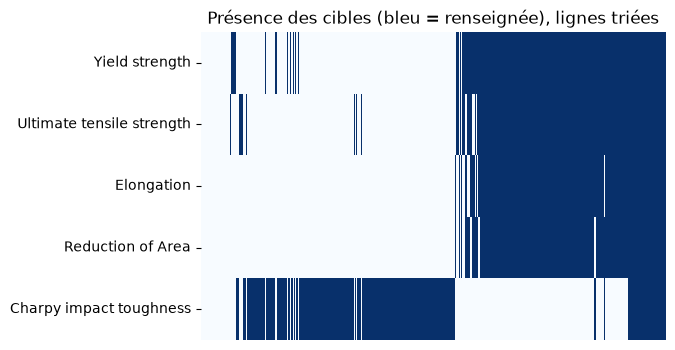

In [8]:
target_counts = df[TARGETS].notna().sum().rename("nb lignes étiquetées")
print(target_counts.to_string())
print(f"\nLignes avec au moins une cible : {df[TARGETS].notna().any(axis=1).sum()}")
print(f"Lignes avec toutes les cibles  : {df[TARGETS].notna().all(axis=1).sum()}")
print(f"Lignes sans aucune cible       : {df[TARGETS].isna().all(axis=1).sum()}")

plt.figure(figsize=(6, 4))
sns.heatmap(df[TARGETS].notna().T.astype(int).loc[:, df[TARGETS].notna().sum(axis=1).sort_values().index],
            cbar=False, cmap="Blues", xticklabels=False)
plt.title("Présence des cibles (bleu = renseignée), lignes triées")
plt.show()

## 2. Outliers (méthode IQR du cours)

Méthode de Tukey (1977) vue en CM0 : une valeur est atypique si elle est hors de $[Q_1 - 1.5\,IQR \; ; \; Q_3 + 1.5\,IQR]$.

Le cours distingue deux cas : **erreur de mesure** (→ traiter comme une valeur manquante) ou **situation extraordinaire** (→ garder). Ici, beaucoup de « outliers » statistiques sont des **aciers volontairement alliés** (ex. soudures 9Cr-1Mo avec ~9 % de chrome) ou des traitements thermiques particuliers : ce sont des cas réels, pas des erreurs. On **détecte sans supprimer**, et on vérifie seulement les valeurs physiquement impossibles.

In [9]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.DataFrame({
    "nb outliers IQR": df[FEATURES_NUM + TARGETS].apply(iqr_outliers),
    "min": df[FEATURES_NUM + TARGETS].min(),
    "médiane": df[FEATURES_NUM + TARGETS].median(),
    "max": df[FEATURES_NUM + TARGETS].max(),
    "unité": correspondance_between_names_units.loc[correspondance_between_names_units['Feature'].isin(FEATURES_NUM + TARGETS), 'Unit' ].to_list(),
}).sort_values("nb outliers IQR", ascending=False)
out

,nb outliers IQR,min,médiane,max,unité
Interpass temperature,588,2.000000e+01,200.00000,300.0000,deg C
Current,310,1.150000e+02,170.00000,900.0000,A
Vanadium concentration,176,0.000000e+00,0.00500,2.5000,(weight%)
Nitrogen concentration,172,2.100000e-03,0.00820,0.0552,weight %
Heat input,161,6.000000e-01,1.00000,7.9000,kJ/mm
Oxygen concentration,156,1.320000e-02,0.04230,0.1650,weight %
Silicon concentration,153,4.000000e-02,0.32000,1.1400,(weight%)
Sulphur concentration,126,1.000000e-03,0.00700,0.1400,(weight%)
Nickel concentration,126,0.000000e+00,0.06700,3.5000,(weight%)
Chromium concentration,120,0.000000e+00,0.53000,10.2000,(weight%)


In [10]:
# Contrôles de cohérence physique (valeurs impossibles = erreurs)
checks = {
    "concentration négative": (df[CHEMISTRY] < 0).any(axis=1),
    "UTS < limite d'élasticité": df["Ultimate tensile strength"] < df["Yield strength"],
    "pourcentage > 100": (df[["Elongation", "Reduction of Area"]] > 100).any(axis=1),
}
pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="nb lignes")

concentration négative       0
UTS < limite d'élasticité    0
pourcentage > 100            0
Name: nb lignes, dtype: int64

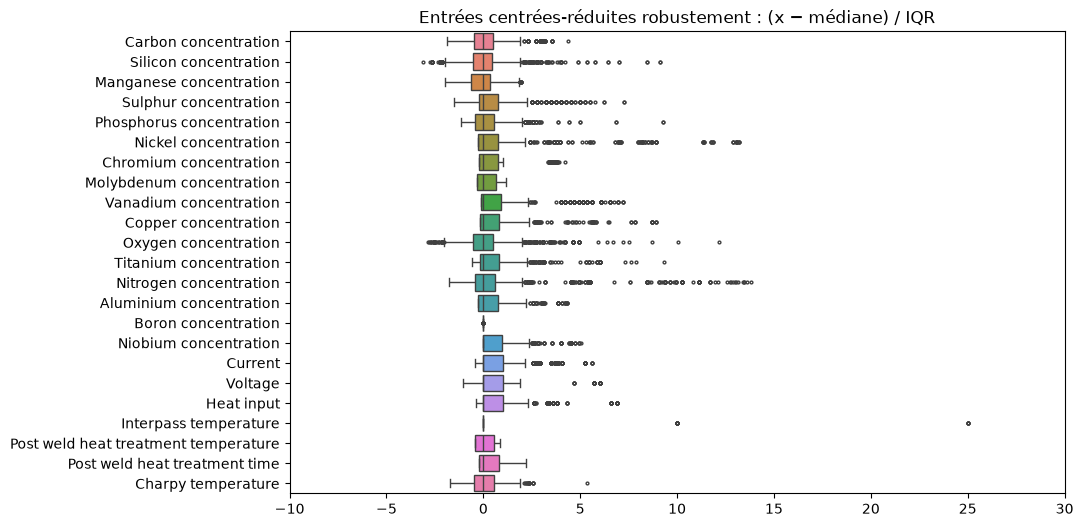

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
z = (df[FEATURES_NUM] - df[FEATURES_NUM].median()) / (df[FEATURES_NUM].quantile(.75) - df[FEATURES_NUM].quantile(.25)).replace(0, 1)
sns.boxplot(data=z, orient="h", ax=ax, fliersize=2)
ax.set_xlim(-10, 30)
ax.set_title("Entrées centrées-réduites robustement : (x − médiane) / IQR")
plt.show()

## 3. Analyse descriptive

### 3.a Distribution des cibles

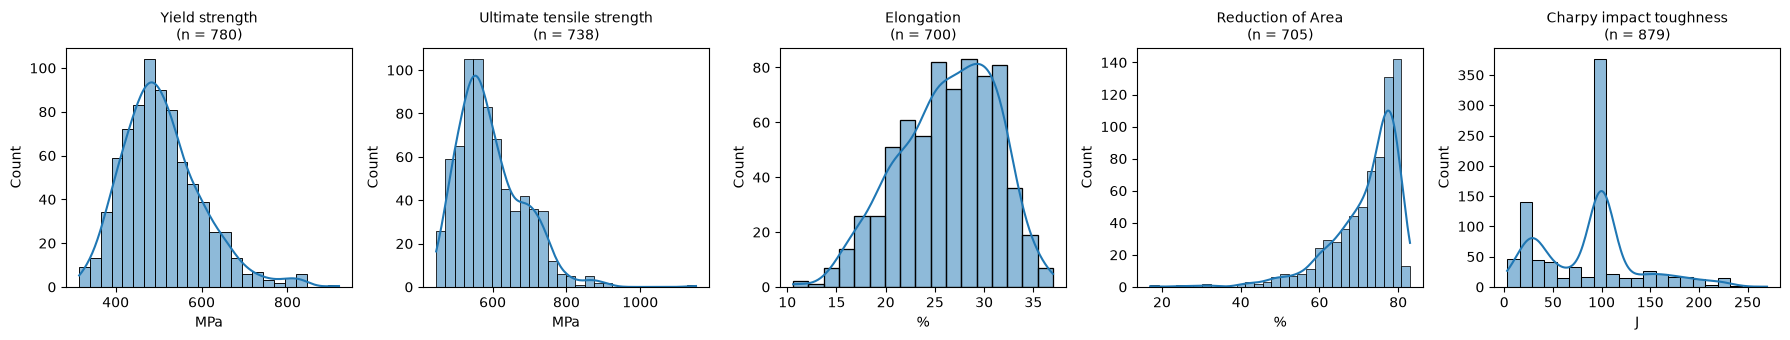

,count,mean,std,min,25%,50%,75%,max
Yield strength,780.0,508.6,92.9,315.0,443.0,495.0,559.2,920.0
Ultimate tensile strength,738.0,594.4,88.6,447.0,532.8,575.5,647.0,1151.0
Elongation,700.0,26.3,4.9,10.6,22.8,26.8,30.0,37.0
Reduction of Area,705.0,71.8,8.9,17.0,68.0,75.0,78.0,83.0
Charpy impact toughness,879.0,87.7,50.1,3.0,38.0,100.0,100.0,270.0


In [12]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(18, 3.5))
for ax, t in zip(axes, TARGETS):
    sns.histplot(df[t].dropna(), ax=ax, kde=True)
    ax.set_title(f"{t}\n(n = {df[t].notna().sum()})", fontsize=10)
    ax.set_xlabel(correspondance_between_names_units.loc[correspondance_between_names_units['Feature'] == t, 'Unit'].values[0])
plt.tight_layout()
plt.show()

df[TARGETS].describe().T.round(1)

**⚠️ Point important sur la ténacité Charpy**

La distribution de `Charpy impact toughness` a deux pics anormaux : **356 valeurs valent exactement 100 J et 118 exactement 28 J**, alors que la température d'essai correspondante varie beaucoup (de −85 °C à +59 °C). Ce n'est pas un hasard : dans beaucoup de publications (notamment la série *Evans*), on ne rapporte pas « l'énergie mesurée à une température donnée » mais **« la température à laquelle la soudure atteint 100 J (ou 28 J) »** — les températures de transition classiques T₁₀₀J et T₂₈J.

Conséquence : pour ces lignes, l'information est dans `Charpy temperature`, pas dans `Charpy impact toughness`. Prédire directement l'énergie Charpy mélangerait deux types de mesure. **Options à discuter en équipe** :
1. garder l'énergie comme cible et la température comme entrée (simple, mais le modèle apprendra surtout « 100 J » par cœur) ;
2. **prédire la température de transition T₁₀₀J** sur les lignes où l'énergie vaut 100 J (cible plus homogène et plus parlante pour un industriel : plus T₁₀₀J est basse, plus la soudure reste tenace à froid) ;
3. transformer en classification : « tenace / fragile » selon que l'énergie dépasse un seuil à une température donnée.

356 valeurs à 100 J et 118 à 28 J sur 879 valeurs Charpy


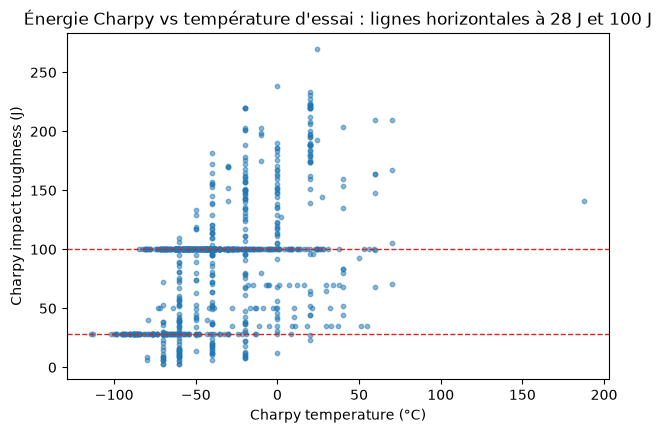

In [13]:
c = df["Charpy impact toughness"]
print(f"{(c == 100).sum()} valeurs à 100 J et {(c == 28).sum()} à 28 J sur {c.notna().sum()} valeurs Charpy")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(df["Charpy temperature"], c, s=10, alpha=.5)
for level in (28, 100):
    ax.axhline(level, ls="--", color="C3", lw=1)
ax.set_xlabel("Charpy temperature (°C)"); ax.set_ylabel("Charpy impact toughness (J)")
ax.set_title("Énergie Charpy vs température d'essai : lignes horizontales à 28 J et 100 J")
plt.show()

### 3.b Corrélations

On utilise la corrélation de **Spearman** (sur les rangs) plutôt que Pearson : elle capte les relations monotones non linéaires et est peu sensible aux outliers relevés en section 4. Chaque coefficient est calculé sur les paires de valeurs disponibles (*pairwise*) : les coefficients reposent donc sur des effectifs différents, à garder en tête pour l'interprétation.

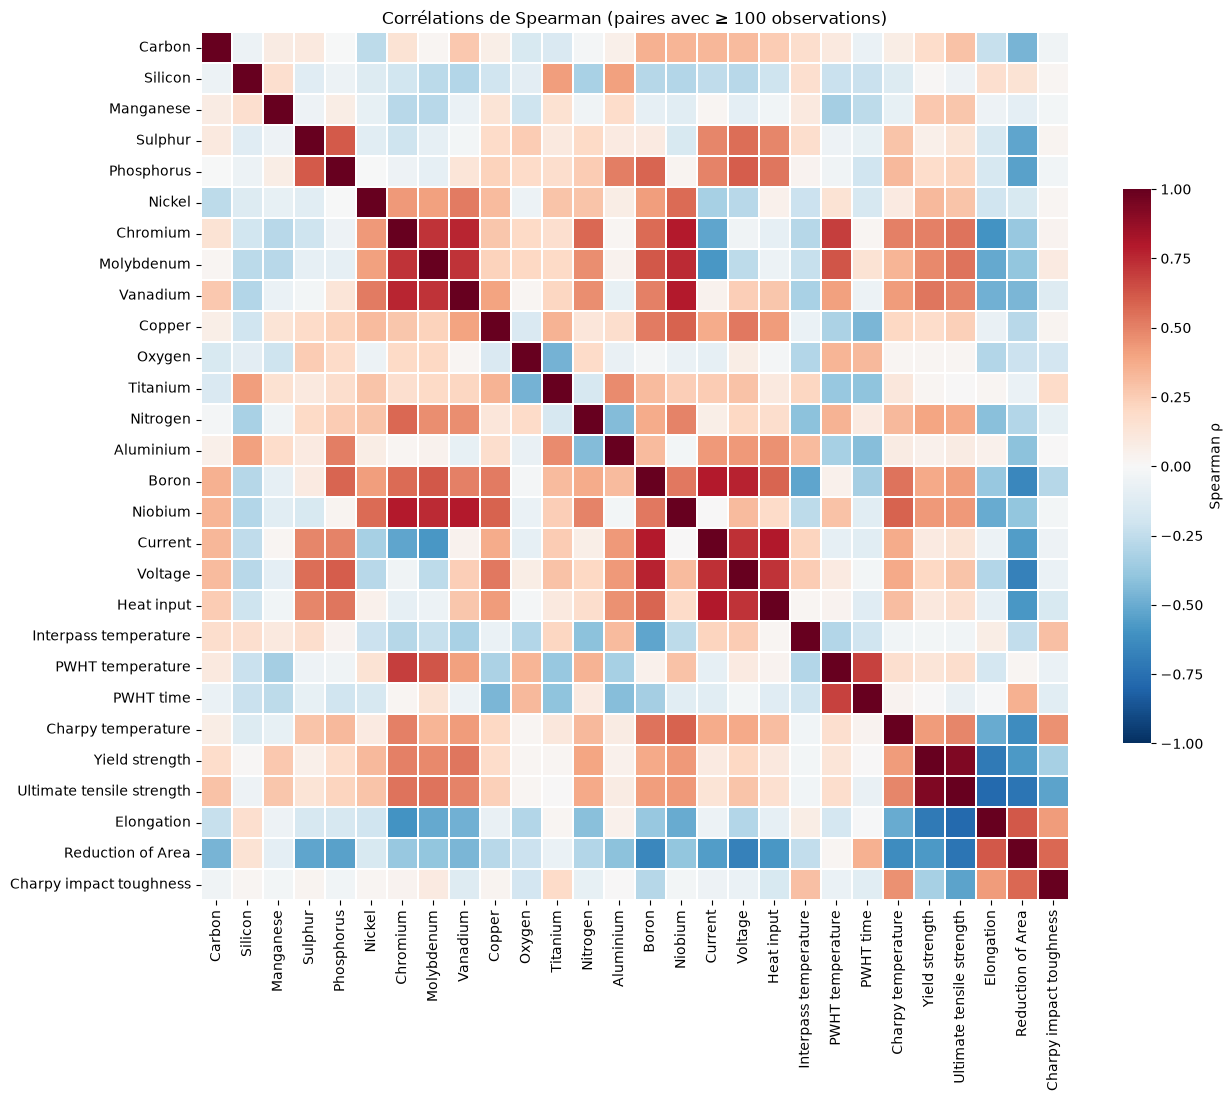

In [14]:
corr = df[FEATURES_NUM + TARGETS].corr(method="spearman", min_periods=100)
short = lambda c: c.replace(" concentration", "").replace("Post weld heat treatment", "PWHT")
corr = corr.rename(index=short, columns=short)

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=.3,
            cbar_kws={"shrink": .6, "label": "Spearman ρ"})
plt.title("Corrélations de Spearman (paires avec ≥ 100 observations)")
plt.show()

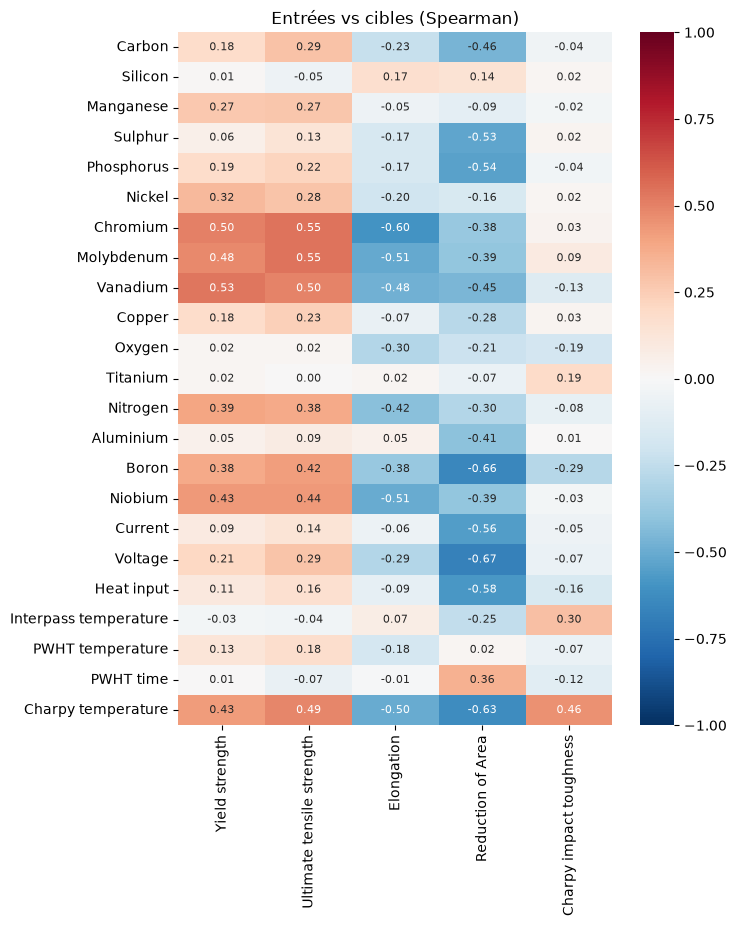

In [15]:
# Corrélation de chaque entrée avec chaque cible
corr_targets = corr.loc[[short(c) for c in FEATURES_NUM], [short(t) for t in TARGETS]]
plt.figure(figsize=(7, 9))
sns.heatmap(corr_targets, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("Entrées vs cibles (Spearman)")
plt.show()

### 3.c Analyse en Composantes Principales

**But** : développer de l'intuition sur la structure des **entrées** (le sujet le demande explicitement) : quelles variables varient ensemble, y a-t-il des groupes de soudures, des individus atypiques ?

Choix (cours CM2) :
- ACP sur les **entrées uniquement** (non supervisée ; les cibles serviront juste à colorer les points) ;
- variables **standardisées** : sinon les variables en ppm ou en °C (grandes variances) domineraient celles en % massique (cf. l'exemple *USArrests* du cours, où `Assault` écrase tout sans standardisation) ;
- **imputation par la médiane** avant l'ACP, uniquement pour cette exploration (l'ACP ne gère pas les NaN). Elle écrase la variance des variables très manquantes : à mentionner dans le rapport comme limite.
- nombre de composantes : règle des **80 % de variance cumulée**, **coude** de l'histogramme, **critère de Kaiser** (λ > 1 sur données centrées-réduites).

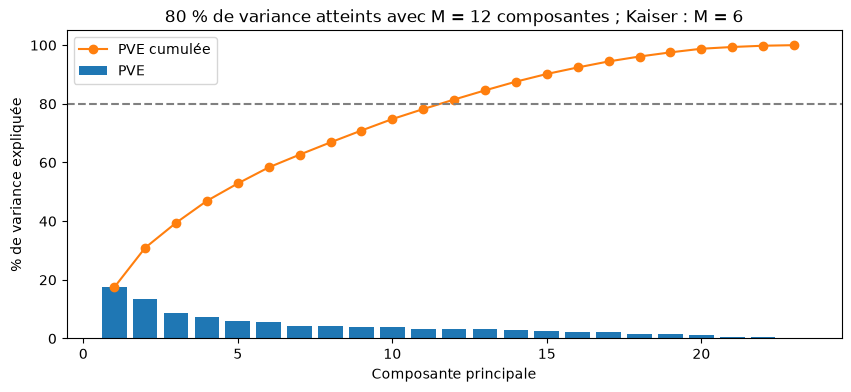

In [16]:
X_pca_in = df[FEATURES_NUM ]
pca_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("pca", PCA()),
])
scores = pca_pipe.fit_transform(X_pca_in)
pca = pca_pipe.named_steps["pca"]
pve = pca.explained_variance_ratio_
eig = pca.explained_variance_

M80 = int(np.argmax(np.cumsum(pve) >= 0.80) + 1)
M_kaiser = int((eig > 1).sum())

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, len(pve) + 1), pve * 100, label="PVE")
ax.plot(range(1, len(pve) + 1), np.cumsum(pve) * 100, "o-", color="C1", label="PVE cumulée")
ax.axhline(80, ls="--", color="grey")
ax.set_xlabel("Composante principale"); ax.set_ylabel("% de variance expliquée")
ax.set_title(f"80 % de variance atteints avec M = {M80} composantes ; Kaiser : M = {M_kaiser}")
ax.legend()
plt.show()

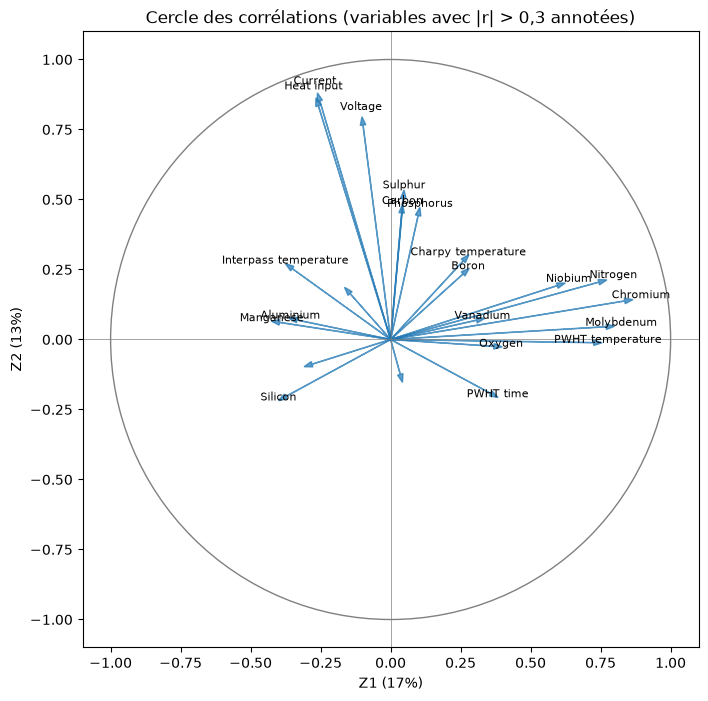

In [17]:
# Cercle des corrélations Z1/Z2 : corr(Z_m, X_j)
X_std = pca_pipe[:-1].transform(X_pca_in)
circle = pd.DataFrame(
    [[np.corrcoef(X_std[:, j], scores[:, m])[0, 1] for m in (0, 1)] for j in range(X_std.shape[1])],
    index=[short(c) for c in X_pca_in.columns], columns=["Z1", "Z2"])

fig, ax = plt.subplots(figsize=(8, 8))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for name, (x, y) in circle.iterrows():
    ax.arrow(0, 0, x, y, head_width=0.02, color="C0", alpha=.7)
    if np.hypot(x, y) > 0.3:
        ax.text(x * 1.07, y * 1.07, name, fontsize=8, ha="center")
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
ax.axhline(0, color="grey", lw=.5); ax.axvline(0, color="grey", lw=.5)
ax.set_xlabel(f"Z1 ({pve[0]:.0%})"); ax.set_ylabel(f"Z2 ({pve[1]:.0%})")
ax.set_title("Cercle des corrélations (variables avec |r| > 0,3 annotées)")
plt.show()

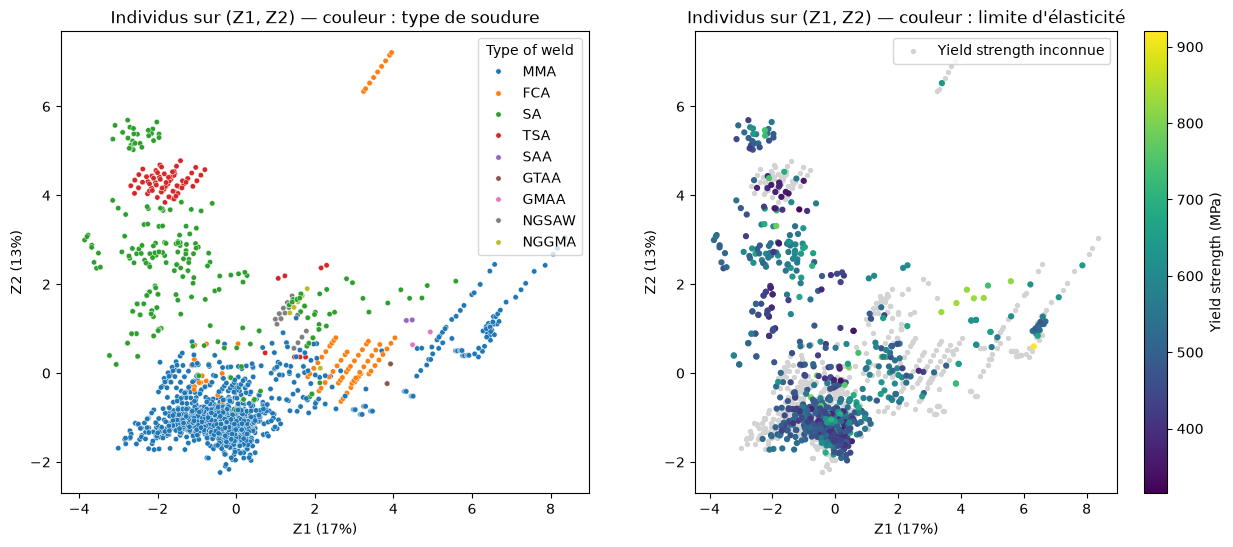

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=df["Type of weld"], s=15, ax=axes[0])
axes[0].set_title("Individus sur (Z1, Z2) — couleur : type de soudure")

lab = df["Yield strength"].notna()
axes[1].scatter(scores[~lab, 0], scores[~lab, 1], s=8, c="lightgrey", label="Yield strength inconnue")
sc = axes[1].scatter(scores[lab, 0], scores[lab, 1], s=12, c=df.loc[lab, "Yield strength"], cmap="viridis")
plt.colorbar(sc, ax=axes[1], label="Yield strength (MPa)")
axes[1].legend(loc="upper right"); axes[1].set_title("Individus sur (Z1, Z2) — couleur : limite d'élasticité")
for ax in axes:
    ax.set_xlabel(f"Z1 ({pve[0]:.0%})"); ax.set_ylabel(f"Z2 ({pve[1]:.0%})")
plt.show()

##### A. Variables contributives à Z1 et Z2

**Z1 (17 %) : axe « composition de l'alliage / traitement thermique »**
- Côté positif (flèches les plus longues) : **Chromium** ($r \approx 0{,}85$), **Molybdenum** ($\approx 0{,}8$), **Nitrogen** ($\approx 0{,}78$), **PWHT temperature** ($\approx 0{,}75$) et **Niobium** ($\approx 0{,}6$). Plus faiblement ($\approx 0{,}3$–$0{,}4$) : Vanadium, Oxygen et PWHT time.
- Côté négatif (corrélations moyennes, $\approx -0{,}4$) : **Manganese**, **Aluminium**, **Silicon** et **Interpass temperature**.

**Z2 (13 %) : axe « énergie de soudage »**
- **Current** et **Heat input** ($\approx 0{,}85$), puis **Voltage** ($\approx 0{,}8$). Avec Chromium, ce sont les variables les mieux représentées du plan (flèches proches du cercle). Current et Heat input penchent aussi légèrement du côté négatif de Z1 ($\approx -0{,}25$).
- Contribution plus modeste : **Sulphur**, **Carbon** et **Phosphorus** ($\approx 0{,}5$).

**Variables liées aux deux axes**
- **Charpy temperature** et **Boron** ($\approx 0{,}25$–$0{,}3$ sur chaque axe) pointent en diagonale, entre le groupe Cr-Mo et le groupe énergie.
- **Interpass temperature** ($Z_1 \approx -0{,}4$, $Z_2 \approx 0{,}25$) se rapproche des variables d'énergie de soudage.
- **Silicon** et **PWHT time** ont une petite composante négative sur Z2 ($\approx -0{,}2$).

**Éléments d'alliage associés**
- **Cr–Mo–Nb–N–V**, accompagnés de PWHT temperature et PWHT time : cette combinaison évoque les aciers **9Cr-1Mo modifiés (type P91/T91)**, résistants au fluage. Ces aciers exigent un traitement thermique post-soudage, ce qui explique que les variables PWHT pointent dans la même direction.
- **Mn–Si–Al**, en opposition : désoxydants typiques des métaux fondus C-Mn ou faiblement alliés. Z1 oppose donc deux familles d'aciers.
- **C–S–P** : petit groupe orienté vers Z2 (impuretés et teneur en carbone), avec des corrélations modérées. Leur proximité avec les variables d'énergie suggère que les procédés à fort apport de chaleur sont représentés par des aciers plus chargés en C, S et P dans la base. C'est à interpréter avec prudence.

> ⚠️ Les flèches courtes, proches du centre du cercle (les trois flèches non annotées, $|r| < 0{,}3$), sont mal représentées dans ce plan et ne doivent pas être interprétées.

##### B. Les types de soudure forment-ils des groupes ?

**Oui, en partie :**
- **MMA** forme un amas dense en bas au centre ($Z_1 \approx -3$ à $1$, $Z_2 \approx -2$ à $0{,}5$). Il se prolonge par une traînée en diagonale vers la droite ($Z_1$ jusqu'à $\approx 8$, $Z_2$ jusqu'à $\approx 3$), qui correspond vraisemblablement aux soudures MMA sur aciers Cr-Mo.
- **SA** et **TSA** sont nettement situés en haut à gauche ($Z_1 < 0$, $Z_2 \approx 2$ à $6$). C'est cohérent avec le cercle des corrélations, puisque Current et Heat input pointent dans cette direction, et avec le soudage à l'arc submergé, qui travaille à forte intensité et fort apport de chaleur. TSA forme un groupe compact ($Z_1 \approx -2$ à $-0{,}5$, $Z_2 \approx 3{,}5$ à $5$). SA est plus étalé, avec quelques points vers $Z_1 \approx 0$–$4$, $Z_2 \approx 1$–$2{,}5$.
- **FCA** forme des **alignements rectilignes** dans la zone $Z_1 \approx 2$–$4{,}5$, $Z_2 \approx -1$ à $1{,}5$, ainsi qu'un groupe isolé tout en haut ($Z_1 \approx 3{,}5$–$4$, $Z_2 \approx 6{,}5$–$7$). Des points alignés correspondent souvent à une même série d'essais où un seul paramètre varie (même acier, apport de chaleur ou PWHT différent), probablement issue d'une même publication.
- Les procédés rares (SAA, GTAA, GMAA, NGSAW, NGGMA) comptent trop peu de points pour former des groupes. Ils sont situés dans la zone intermédiaire ($Z_1 \approx 1$–$5$, $Z_2 \approx -0{,}5$–$2$).

**Conclusion :** le type de soudure est une **variable structurante**, au moins pour distinguer MMA de SA/TSA. Il est toutefois en grande partie redondant avec Current, Voltage et Heat input, qui portent Z2. Les classes rares ne sont pas séparables visuellement.

> Si le type de soudure fait partie des variables de l'ACP, cette séparation est en partie obtenue par construction. Elle n'est une observation indépendante que s'il est utilisé uniquement pour colorer les points.

##### C. Recouvrement des lignes non étiquetées (gris) et étiquetées

**Globalement oui, mais pas partout.**
- La majorité des points gris se trouve dans l'amas MMA central et à sa périphérie, mêlée aux points étiquetés. Les groupes SA et TSA en haut à gauche sont eux aussi mélangés. C'est **favorable au semi-supervisé**.
- Certaines **zones sont majoritairement grises** :
  - les **alignements FCA** ($Z_1 \approx 2$–$4{,}5$, $Z_2 \approx -1$ à $1{,}5$) ;
  - le **groupe isolé en haut** ($Z_1 \approx 3{,}5$–$4$, $Z_2 \approx 6{,}5$–$7$), qui ne compte qu'un seul point étiqueté ;
  - l'**extrémité de la traînée MMA Cr-Mo** ($Z_1 \approx 7$–$8{,}5$, $Z_2 \approx 2$–$3$), entièrement grise. Seul un petit groupe vers $Z_1 \approx 6{,}5$, $Z_2 \approx 1$ est étiqueté.
- Dans ces zones, le modèle semi-supervisé devrait **extrapoler**, et les pseudo-labels y seraient peu fiables. Le risque est accru par le fait que la partie droite du plan contient les limites d'élasticité les plus élevées ($\approx 700$–$900$ MPa, autour de $Z_1 \approx 4$–$6{,}5$), avec très peu de points étiquetés.

> Les points gris sont les lignes dont la limite d'élasticité est inconnue. Ils incluent les soudures testées uniquement en Charpy, qui forment une population en partie différente.
>
> Un recouvrement en 2D est **nécessaire mais pas suffisant** : deux nuages superposés dans le plan peuvent se séparer sur d'autres axes. Pour le vérifier, on peut entraîner un classifieur « étiqueté vs non étiqueté » sur l'ensemble des variables : une AUC proche de 0,5 indiquerait des distributions similaires.

##### D. Le % de variance de (Z1, Z2) est-il suffisant ?

**Non, pas pour une représentation globalement fiable.**
- $Z_1 + Z_2 \approx 30\,\%$ de la variance totale.
- Il faut **12 composantes** pour atteindre 80 %. Le critère de Kaiser en retient **6**, qui n'expliquent qu'environ 58 % de la variance.
- La décroissance lente de la PVE (aucune composante au-delà de la 3e ne dépasse 9 %) montre que l'information est très dispersée entre les 23 variables.

**Conséquences :**
- Le plan reste **utile en exploration** pour les variables bien représentées (Current, Heat input, Voltage, Cr, Mo, N, PWHT temperature), dont les flèches sont proches du cercle.
- Les **séparations observées sont réelles** : une projection peut fusionner des groupes distincts, mais ne peut pas créer une séparation inexistante. La distinction MMA vs SA/TSA est donc solide.
- Les **recouvrements**, en revanche, ne prouvent rien : les conclusions des parties B et C doivent être nuancées en ce sens.

---

## Enregistrement des données

In [ ]:
df.to_csv(path_data_processed / "welddb_processed_vf.csv", sep=";", index=False)